---
title: "Lab 10: Classifying Heart Attacks"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
---

## Data and Context

We use the clinical measurements in `heart_attack.csv` to predict the doctor's recorded risk diagnosis. Class 1 means at risk, and class 0 means not at risk.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

raw = pd.read_csv(Path("Data") / "heart_attack.csv")

numeric_columns = ["age", "trtbps", "chol", "thalach"]
categorical_columns = ["sex", "cp", "restecg"]

heart = raw.drop_duplicates().reset_index(drop=True)
heart[categorical_columns] = heart[categorical_columns].astype("category")

class_counts = heart["output"].value_counts().sort_index().to_frame("Count")
class_counts["Percent"] = (100 * class_counts["Count"] / len(heart)).round(1)
class_counts.index = ["0 — Not at risk", "1 — At risk"]

print(f"Original rows: {len(raw)}")
print(f"Missing values: {raw.isna().sum().sum()}")
print(f"Exact duplicate rows removed: {raw.duplicated().sum()}")
print(f"Rows used: {len(heart)}")
display(class_counts)
display(heart[numeric_columns].describe().loc[["mean", "std", "min", "50%", "max"]].round(1))

Original rows: 273
Missing values: 0
Exact duplicate rows removed: 1
Rows used: 272


,Count,Percent
0 — Not at risk,127,46.7
1 — At risk,145,53.3


,age,trtbps,chol,thalach
mean,54.4,132.1,247.1,149.4
std,9.1,17.7,52.5,23.2
min,29.0,94.0,126.0,71.0
50%,56.0,130.0,240.0,152.0
max,77.0,200.0,564.0,202.0


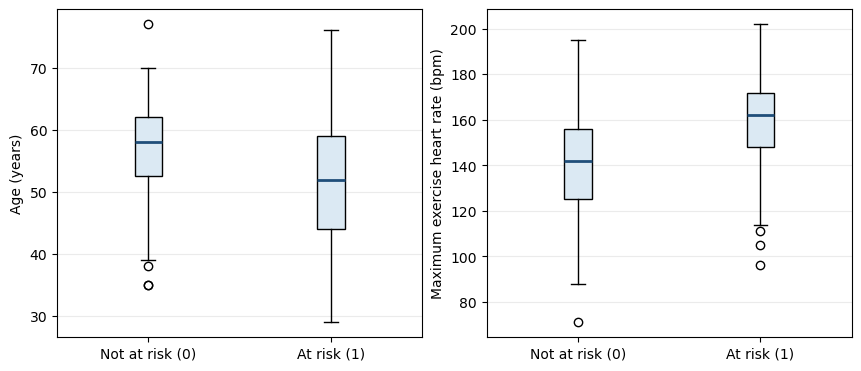

,age,trtbps,chol,thalach
0 — Not at risk,58.0,130.0,249.0,142.0
1 — At risk,52.0,130.0,234.0,162.0


In [2]:
visuals = {"age": "Age (years)", "thalach": "Maximum exercise heart rate (bpm)"}
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6), layout="constrained")

for ax, (column, label) in zip(axes, visuals.items()):
    groups = [heart.loc[heart["output"].eq(value), column] for value in [0, 1]]
    ax.boxplot(groups, patch_artist=True, boxprops={"facecolor": "#dbe9f3"},
               medianprops={"color": "#1f4e79", "linewidth": 2})
    ax.set_xticks([1, 2], ["Not at risk (0)", "At risk (1)"])
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.25)

plt.show()

group_medians = heart.groupby("output")[numeric_columns].median()
group_medians.index = class_counts.index
display(group_medians)

**Answer:** The file had 273 records and no missing values. I removed one exact duplicate so it could not appear in both a training and a validation fold. That left 272 records, with 145 labeled at risk and 127 labeled not at risk. I treated recorded sex, chest pain type, and resting ECG results as categories. The at-risk group was younger in this sample, with a median age of 52 compared with 58, and had a higher median maximum exercise heart rate, 162 compared with 142 bpm.

## Model Fitting

**Answer:** I used balanced accuracy to choose the best version of each model. It averages recall for the at-risk group and specificity for the not-at-risk group, so both groups count equally. I compared four feature sets for each method. The smaller sets let me check whether removing recorded sex, using only numerical measurements, or using just age, chest pain type, and maximum exercise heart rate helped.

I used five outer folds to estimate test performance and a separate five-fold search inside each outer training set to choose features and settings. Both splits were shuffled and stratified to keep the class proportions similar across folds. I one-hot encoded the categorical predictors and standardized the numeric predictors for k-nearest neighbors and logistic regression. The tree used the original numeric units. Each pipeline learned these transformations from its own training fold.

In [3]:
X = heart.drop(columns="output")
y = heart["output"]

feature_sets = {
    "All predictors": numeric_columns + categorical_columns,
    "Without sex": numeric_columns + ["cp", "restecg"],
    "Numeric only": numeric_columns,
    "Age, chest pain, and exercise heart rate": ["age", "cp", "thalach"],
}

models = {
    "k-nearest neighbors": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2],
        },
    ),
    "Logistic regression": (
        LogisticRegression(max_iter=1000),
        {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    ),
    "Decision tree": (
        DecisionTreeClassifier(random_state=42),
        {"model__max_depth": [2, 3, 4, 5, 7, None],
         "model__min_samples_leaf": [2, 5, 10, 15]},
    ),
}

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=73)
outer_splits = list(outer_cv.split(X, y))

def make_search(model_name):
    model, settings = models[model_name]
    grid = []
    for features in feature_sets.values():
        numeric = [column for column in numeric_columns if column in features]
        categorical = [column for column in categorical_columns if column in features]
        scaling = "passthrough" if model_name == "Decision tree" else StandardScaler()
        drop = "first" if model_name == "Logistic regression" else None
        encoding = OneHotEncoder(drop=drop, handle_unknown="ignore", sparse_output=False)
        preprocess = ColumnTransformer(
            [("numeric", scaling, numeric), ("categorical", encoding, categorical)]
        )
        grid.append({"preprocess": [preprocess], **settings})

    pipeline = Pipeline([("preprocess", "passthrough"), ("model", model)])
    return GridSearchCV(pipeline, grid, scoring="balanced_accuracy", cv=inner_cv,
                        error_score="raise")

In [4]:
final_models = {}
oof_predictions = {}
selected_settings = []
feature_scores = {}

for model_name in models:
    search = make_search(model_name)
    predictions = pd.Series(index=y.index, dtype="int64")

    for train, test in outer_splits:
        search.fit(X.iloc[train], y.iloc[train])
        predictions.iloc[test] = search.predict(X.iloc[test])

    oof_predictions[model_name] = predictions.astype(int)

    search.fit(X, y)
    final_models[model_name] = search.best_estimator_

    settings_per_set = len(search.cv_results_["params"]) // len(feature_sets)
    best_index = search.best_index_
    settings = {key.replace("model__", ""): value
                for key, value in search.best_params_.items() if key.startswith("model__")}
    selected_settings.append({
        "Model": model_name,
        "Feature set": list(feature_sets)[best_index // settings_per_set],
        "Settings": ", ".join(f"{key} = {value}" for key, value in settings.items()),
    })
    best_scores = search.cv_results_["mean_test_score"].reshape(len(feature_sets), settings_per_set)
    feature_scores[model_name] = best_scores.max(axis=1)

display(pd.DataFrame(feature_scores, index=feature_sets).round(3))
display(pd.DataFrame(selected_settings).set_index("Model"))

,k-nearest neighbors,Logistic regression,Decision tree
All predictors,0.767,0.777,0.752
Without sex,0.728,0.737,0.757
Numeric only,0.663,0.684,0.693
"Age, chest pain, and exercise heart rate",0.753,0.753,0.753


,Feature set,Settings
Model,,
k-nearest neighbors,All predictors,"n_neighbors = 21, p = 1, weights = uniform"
Logistic regression,All predictors,C = 10
Decision tree,Without sex,"max_depth = 3, min_samples_leaf = 15"


**Answer:** The best k-nearest neighbors model used all predictors, 21 neighbors, Manhattan distance, and equal weights. Logistic regression also used all predictors, with a C of 10. The best decision tree left out recorded sex, had a maximum depth of 3, and required at least 15 observations in each leaf.

The first table shows the best search score for each feature set using all the data. I used that search to fit the final versions. The test estimates below come from predictions for the held-out outer folds, where feature and parameter selection were repeated using only the training rows.

## Test Metrics

I combined the held-out predictions from the five outer folds and counted the outcomes for each model. Recall is the share of actual class 1 records predicted as class 1. Precision is the share of predicted class 1 records that are actually class 1. Specificity is the share of actual class 0 records predicted as class 0.

In [5]:
test_metrics = []
outcomes = []

for model_name, predictions in oof_predictions.items():
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    recall = tp / (tp + fn)
    precision = tp / (tp + fp)
    specificity = tn / (tn + fp)
    test_metrics.append({
        "Model": model_name, "Recall": recall, "Precision": precision,
        "Specificity": specificity, "Balanced accuracy": (recall + specificity) / 2,
    })
    outcomes.append({"Model": model_name, "True positives": tp, "False negatives": fn,
                     "False positives": fp, "True negatives": tn})

metrics = pd.DataFrame(test_metrics).set_index("Model")
counts = pd.DataFrame(outcomes).set_index("Model")

display(metrics.round(3))
display(counts)

,Recall,Precision,Specificity,Balanced accuracy
Model,,,,
k-nearest neighbors,0.731,0.768,0.748,0.74
Logistic regression,0.800,0.779,0.740,0.77
Decision tree,0.697,0.743,0.724,0.71


,True positives,False negatives,False positives,True negatives
Model,,,,
k-nearest neighbors,106,39,32,95
Logistic regression,116,29,33,94
Decision tree,101,44,35,92


## Discussion

### Question 1

The hospital faces severe lawsuits if it deems a patient low risk and the patient later experiences a heart attack.

**Answer:** I would use recall because missing an at-risk patient is the most costly error in this situation. I would recommend logistic regression, which had the highest recall at 0.800. For similar patients, I would expect it to flag about 80 out of every 100 patients whose reference diagnosis is at risk.

### Question 2

The hospital is overfull and wants to reserve beds for patients most in need of monitoring.

**Answer:** I would use precision because the hospital wants a high share of the patients it flags for monitoring to actually be at risk. I would recommend logistic regression. It had the highest precision at 0.779, so I would expect about 78 out of every 100 flagged patients to be at risk in a similar patient group. Its specificity was 0.740, so about 74 out of every 100 low-risk patients would avoid being flagged.

### Question 3

The hospital wants to understand which biological measures are associated with heart attack risk.

In [6]:
logistic = final_models["Logistic regression"]
preprocess = logistic.named_steps["preprocess"]
numeric = preprocess.transformers_[0][2]
names = preprocess.get_feature_names_out()
coefficients = pd.Series(logistic.named_steps["model"].coef_[0], index=names)

# Convert standardized coefficients to odds ratios for a 10-unit increase.
scales = pd.Series(preprocess.named_transformers_["numeric"].scale_, index=numeric)
numeric_coefficients = coefficients.loc[["numeric__" + column for column in numeric]]
numeric_coefficients.index = numeric
odds_ratios = np.exp(10 * numeric_coefficients / scales)

measure_names = {"age": "Age, per 10 years", "trtbps": "Resting BP, per 10 mm Hg",
                 "chol": "Cholesterol, per 10 mg/dL",
                 "thalach": "Maximum exercise heart rate, per 10 bpm"}

display(odds_ratios.rename(index=measure_names).to_frame("Adjusted odds ratio").round(3))

,Adjusted odds ratio
"Age, per 10 years",0.776
"Resting BP, per 10 mm Hg",0.822
"Cholesterol, per 10 mg/dL",0.944
"Maximum exercise heart rate, per 10 bpm",1.406


**Answer:** I would use balanced accuracy as a check on predictive performance and choose a model whose associations I can explain. Logistic regression had the highest balanced accuracy at 0.770. Holding the other predictors fixed, a 10 bpm higher maximum exercise heart rate was associated with 1.41 times the odds of an at-risk diagnosis. Age, resting blood pressure, and cholesterol had negative associations in this fitted model. These estimates describe associations with the recorded diagnosis. A study designed to establish causation would be needed to identify root causes.

### Question 4

The hospital wants to compare diagnoses from new doctors with the algorithm's predictions.

**Answer:** I would use balanced accuracy to give correct diagnoses in both risk groups equal weight. I would use logistic regression as the benchmark because it had the highest balanced accuracy, about 0.770 on similar cases. Its estimated recall was 0.800 and its specificity was 0.740. I would have the doctors and the model assess the same new cases and score both against the same independent reference diagnoses.